# 02 — Pelatihan Model
Tiga CNN *pretrained* ImageNet di-*fine-tune* pada tiga skenario:

| Skenario | Perlakuan |
|---|---|
| 1 | Data asli |
| 2 | Augmentasi data latih (rotasi ±10°, geser 5%, zoom 0,9–1,1, kecerahan/kontras ±20%) |
| 3 | CLAHE + augmentasi |

Model: **MobileNetV2**, **EfficientNet-B0**, **DenseNet121**. Keluaran *Global Average Pooling* dipakai sebagai
*embedding* temu kembali. Setiap konfigurasi diulang dengan 3 *seed* (42, 7, 123).

> Pelatihan seluruh 27 model memakan waktu sekitar 2 jam di GPU RTX 4050. Secara bawaan notebook ini **tidak**
> melatih ulang (`JALANKAN_PELATIHAN = False`) dan menampilkan hasil pelatihan yang sudah tersimpan agar angka sama
> dengan laporan. Ubah menjadi `True` untuk melatih ulang; hasilnya disimpan di `notebook/hasil/runs/`.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

PROJECT = Path.cwd().parent                      # folder "Tugas Temu Kembali Citra"
RAW_DIR = PROJECT / "data pneumonia" / "chest_xray"
DATA_DIR = PROJECT / "data"                      # split dan cache citra hasil persiapan data
OUTPUTS = PROJECT / "outputs"                    # model dan hasil eksperimen
HASIL = Path("hasil")                            # keluaran notebook (terpisah dari outputs/)
HASIL.mkdir(exist_ok=True)
CLASSES = ["Normal", "Bacteria", "Virus"]
NAMA_KELAS = {"Normal": "Normal", "Bacteria": "Pneumonia Bakteri", "Virus": "Pneumonia Virus"}
print("Folder project:", PROJECT)

Folder project: C:\Users\LENOVO\Documents\Temu Kembali Citra\Tugas\Tugas Temu Kembali Citra


In [2]:
import json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import f1_score

JALANKAN_PELATIHAN = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Perangkat:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

Perangkat: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Skenario, augmentasi, dan dataset

In [3]:
SCENARIOS = {"s1_original": ("original", False), "s2_augment": ("original", True), "s3_clahe_augment": ("clahe", True)}
MODELS = ["mobilenet_v2", "efficientnet_b0", "densenet121"]
MODEL_LABELS = {"mobilenet_v2": "MobileNetV2", "efficientnet_b0": "EfficientNet-B0", "densenet121": "DenseNet121"}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def build_transform(augment, train):
    steps = [transforms.Resize((224, 224))]
    if augment and train:   # tanpa flip horizontal: posisi jantung tidak simetris
        steps += [transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                  transforms.ColorJitter(brightness=0.2, contrast=0.2)]
    steps += [transforms.Grayscale(3), transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    return transforms.Compose(steps)

class XrayDataset(Dataset):
    def __init__(self, df, cache_sub, transform):
        self.paths = [DATA_DIR / "cache" / cache_sub / n for n in df["cache_name"]]
        self.labels = df["label_idx"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("L")), self.labels[i]

splits = pd.read_csv(DATA_DIR / "splits.csv")
splits.groupby("split").size()

split
test      915
train    4030
val       879
dtype: int64

## 2. Arsitektur: backbone CNN + embedding + head klasifikasi

In [4]:
class RetrievalNet(nn.Module):
    def __init__(self, arch, num_classes=3, pretrained=True):
        super().__init__()
        pool = [nn.AdaptiveAvgPool2d(1), nn.Flatten()]
        w = "IMAGENET1K_V1" if pretrained else None
        if arch == "mobilenet_v2":
            m = models.mobilenet_v2(weights=w); self.backbone, dim = nn.Sequential(m.features, *pool), 1280
        elif arch == "efficientnet_b0":
            m = models.efficientnet_b0(weights=w); self.backbone, dim = nn.Sequential(m.features, *pool), 1280
        else:
            m = models.densenet121(weights=w); self.backbone, dim = nn.Sequential(m.features, nn.ReLU(), *pool), 1024
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim, num_classes))
    def embed(self, x):          # embedding untuk temu kembali
        return self.backbone(x)
    def forward(self, x):        # prediksi kelas untuk fine-tuning
        return self.head(self.embed(x))

for a in MODELS:
    n = sum(p.numel() for p in RetrievalNet(a, pretrained=False).parameters()) / 1e6
    print(f"{MODEL_LABELS[a]:16s} {n:5.1f} juta parameter")

MobileNetV2        2.2 juta parameter
EfficientNet-B0    4.0 juta parameter


DenseNet121        7.0 juta parameter


## 3. Fungsi pelatihan
AdamW (lr 1e-4), *cosine annealing*, *batch* 32, *mixed precision*, *weighted cross-entropy*, *early stopping*
(patience 5) berdasarkan **macro F1 validasi**. Data uji tidak dipakai sama sekali saat pelatihan.

In [5]:
def train_model(scenario, arch, seed=42, epochs=20, patience=5, out_dir=HASIL / "runs"):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    cache_sub, augment = SCENARIOS[scenario]
    tr, va = splits[splits.split == "train"], splits[splits.split == "val"]
    dl_tr = DataLoader(XrayDataset(tr, cache_sub, build_transform(augment, True)), 32, shuffle=True, drop_last=True)
    dl_va = DataLoader(XrayDataset(va, cache_sub, build_transform(augment, False)), 32)
    counts = np.bincount(tr["label_idx"], minlength=3)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(counts.sum() / (3 * counts), dtype=torch.float32, device=DEVICE))
    model = RetrievalNet(arch).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    run = out_dir / f"{scenario}__{arch}__seed{seed}"; run.mkdir(parents=True, exist_ok=True)
    best, wait, hist = -1, 0, []
    for ep in range(1, epochs + 1):
        model.train()
        for x, y in dl_tr:
            x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad()
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        model.eval(); pred, true = [], []
        with torch.no_grad():
            for x, y in dl_va:
                pred.append(model(x.to(DEVICE)).argmax(1).cpu()); true.append(y)
        f1 = f1_score(torch.cat(true), torch.cat(pred), average="macro")
        hist.append({"epoch": ep, "val_macro_f1": f1}); print(f"epoch {ep:02d} val_macro_f1={f1:.4f}")
        if f1 > best:
            best, wait = f1, 0; torch.save(model.state_dict(), run / "best.pt")
        else:
            wait += 1
            if wait >= patience: break
    pd.DataFrame(hist).to_csv(run / "history.csv", index=False)
    return best

if JALANKAN_PELATIHAN:
    for sc in SCENARIOS:
        for a in MODELS:
            for s in (42, 7, 123):
                train_model(sc, a, seed=s)
else:
    print("Pelatihan dilewati; memakai model tersimpan di", OUTPUTS / "runs")

Pelatihan dilewati; memakai model tersimpan di C:\Users\LENOVO\Documents\Temu Kembali Citra\Tugas\Tugas Temu Kembali Citra\outputs\runs


## 4. Kurva pelatihan (seed 42) dan konfigurasi tersimpan

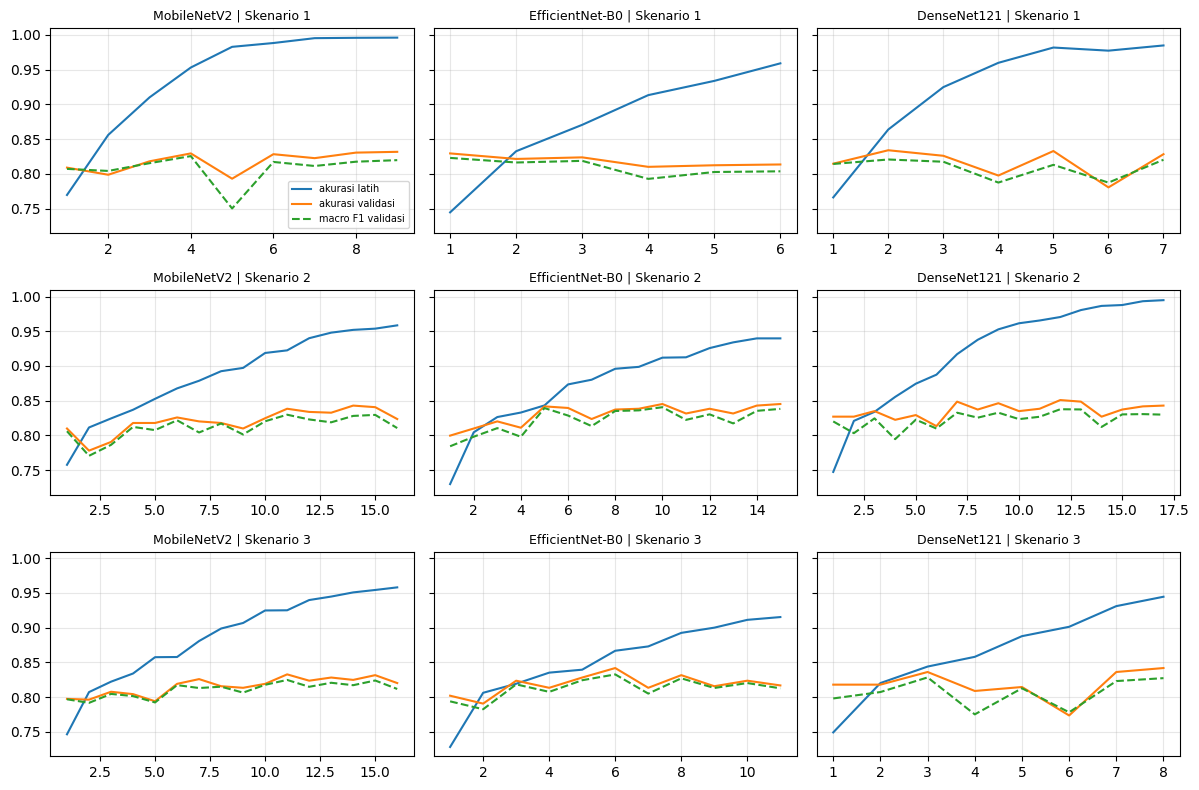

,scenario,model,epochs_run,best_epoch,train_minutes
0,s1_original,mobilenet_v2,9,4,2.04
1,s1_original,efficientnet_b0,6,1,1.77
2,s1_original,densenet121,7,2,3.01
3,s2_augment,mobilenet_v2,16,11,2.96
4,s2_augment,efficientnet_b0,15,10,3.44
5,s2_augment,densenet121,17,12,6.71
6,s3_clahe_augment,mobilenet_v2,16,11,3.23
7,s3_clahe_augment,efficientnet_b0,11,6,2.70
8,s3_clahe_augment,densenet121,8,3,3.45


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharey=True)
for r, sc in enumerate(SCENARIOS):
    for c, a in enumerate(MODELS):
        h = pd.read_csv(OUTPUTS / "runs" / f"{sc}__{a}" / "history.csv")
        ax = axes[r, c]
        ax.plot(h.epoch, h.train_acc, label="akurasi latih"); ax.plot(h.epoch, h.val_acc, label="akurasi validasi")
        ax.plot(h.epoch, h.val_macro_f1, "--", label="macro F1 validasi")
        ax.set_title(f"{MODEL_LABELS[a]} | Skenario {r + 1}", fontsize=9); ax.grid(alpha=.3)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

cfg = [json.loads((OUTPUTS / "runs" / f"{sc}__{a}" / "config.json").read_text()) for sc in SCENARIOS for a in MODELS]
pd.DataFrame(cfg)[["scenario", "model", "epochs_run", "best_epoch", "train_minutes"]].round(2)

## 5. Rata-rata ± simpangan baku tiga seed (data uji)

In [7]:
seed = pd.read_csv(OUTPUTS / "extra" / "seed_summary.csv")
tabel = pd.DataFrame({"Skenario": seed["Skenario"], "Model": seed["Model"]})
for k in ["Val Macro F1", "Akurasi", "Macro F1", "Macro AUC", "P@10", "mAP"]:
    tabel[k] = [f"{m*100:.1f} ± {s*100:.1f}" for m, s in zip(seed[f"{k} mean"], seed[f"{k} std"])]
best = json.loads((OUTPUTS / "best_run.json").read_text())
print("Proposed model (rata-rata macro F1 validasi tertinggi):", best)
tabel

Proposed model (rata-rata macro F1 validasi tertinggi): {'scenario': 's2_augment', 'model': 'densenet121', 'tag': 'seed7', 'seed': 7}


,Skenario,Model,Val Macro F1,Akurasi,Macro F1,Macro AUC,P@10,mAP
0,Skenario 1 (Original),MobileNetV2,83.0 ± 0.4,79.9 ± 0.2,80.4 ± 0.4,91.5 ± 0.4,80.2 ± 1.8,80.1 ± 5.2
1,Skenario 1 (Original),EfficientNet-B0,82.7 ± 0.4,79.2 ± 1.3,79.4 ± 1.8,91.4 ± 1.1,77.7 ± 2.2,77.0 ± 6.6
2,Skenario 1 (Original),DenseNet121,82.8 ± 0.7,79.9 ± 0.9,79.8 ± 1.1,91.3 ± 0.1,79.6 ± 1.2,81.2 ± 4.0
3,Skenario 2 (Augmentasi),MobileNetV2,82.8 ± 0.3,80.1 ± 1.2,80.3 ± 0.8,91.7 ± 0.2,79.2 ± 2.1,77.0 ± 3.6
4,Skenario 2 (Augmentasi),EfficientNet-B0,83.4 ± 0.7,80.3 ± 1.7,80.1 ± 2.0,92.2 ± 1.1,80.1 ± 2.6,78.1 ± 4.1
5,Skenario 2 (Augmentasi),DenseNet121,84.0 ± 0.1,80.9 ± 0.8,81.2 ± 0.9,92.0 ± 0.4,80.3 ± 0.4,81.7 ± 2.1
6,Skenario 3 (CLAHE + Augmentasi),MobileNetV2,82.0 ± 0.6,80.2 ± 1.1,80.2 ± 1.3,91.9 ± 0.3,78.3 ± 1.7,76.1 ± 4.0
7,Skenario 3 (CLAHE + Augmentasi),EfficientNet-B0,83.7 ± 0.7,80.9 ± 0.1,80.9 ± 0.1,92.4 ± 0.3,80.5 ± 0.9,79.8 ± 2.0
8,Skenario 3 (CLAHE + Augmentasi),DenseNet121,83.8 ± 1.0,79.6 ± 1.8,79.5 ± 1.6,91.2 ± 0.3,78.7 ± 1.7,79.6 ± 4.2
